# Stage 1 — Membrane Property Prediction

Predicts the four **intermediate** membrane properties from the base formulation
parameters (membrane type, filler type, filler weight %):

| Target | Unit | Usable labels |
|---|---|---|
| Ion Exchange Capacity (IEC) | meq/g | 62 |
| Water Swelling / Uptake | % | 66 |
| Proton Conductivity | S/cm | 59 |
| Thickness | µm | 49 |

**Design decisions**

* One regressor **per target** — the four labels have very different missingness,
  so complete-case training would throw away ~40% of the usable labels.
* Validation is `GroupKFold(5)` **grouped by paper**, so that several weight
  percentages from the same publication never straddle train/test.
* Log transforms for conductivity and thickness (both span orders of magnitude).
* Units are harmonised before training (thickness → µm, conductivity → S/cm).
* Values whose unit cannot be resolved are **masked to NaN and reported**, never guessed.

> **Headline finding:** with only three inputs, the absolute property level of an
> unseen paper is not identifiable — grouped R² is ≈ 0 for three of four targets,
> while a leaky random split reports 0.3–0.5. The dataset *does* contain a real
> dose-response (within-paper r ≈ 0.7 for IEC, 0.5 for conductivity), but the model
> cannot transfer that slope across papers unless a measured series baseline is
> supplied — see §15, where reconstruction R² reaches 0.84–0.90.

Source files: `MFC DATA - STAGE1.csv` (numeric sheet),
`MFC DATA - DATA COLLECTION.csv` (citations → group IDs),
`MFC DATA - DATA STRUCTURE.csv` (unit audit).


## 1. Setup


In [1]:
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.model_selection import GroupKFold, KFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

try:
    from IPython.display import display
except ImportError:                      # plain-script fallback
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# notebook-friendly plotting, Agg when executed as a script
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")

BASE = Path.cwd()
if not (BASE / "MFC DATA - STAGE1.csv").exists():
    BASE = Path(r"C:\Users\HP\Downloads\New folder (2)")

OUT = BASE / "outputs"
FIGS = OUT / "figs"
MODELS = BASE / "models"
for d in (OUT, FIGS, MODELS):
    d.mkdir(parents=True, exist_ok=True)

print("Python  :", __import__("sys").version.split()[0])
print("pandas  :", pd.__version__)
print("sklearn :", __import__("sklearn").__version__)
print("xgboost :", __import__("xgboost").__version__)
print("lightgbm:", __import__("lightgbm").__version__)
print("cwd     :", BASE)


Python  : 3.14.4
pandas  : 3.1.1
sklearn : 1.9.1
xgboost : 3.4.1
lightgbm: 4.7.0
cwd     : /home/selvatharrun/Downloads/models


## 2. Load the raw sheets

`STAGE1.csv` is a spreadsheet export with two junk header rows and two spacer
columns, so we skip to the real header and rename positionally.


In [2]:
STAGE1_PATH = BASE / "MFC DATA - STAGE1.csv"
CITATION_PATH = BASE / "MFC DATA - DATA COLLECTION.csv"
STRUCTURE_PATH = BASE / "MFC DATA - DATA STRUCTURE.csv"

raw = pd.read_csv(STAGE1_PATH, header=2, encoding="utf-8-sig")
print("raw shape:", raw.shape)

# keep only the 12 real columns (drops the merged-cell spacer columns)
raw = raw.iloc[:, :12]
raw.columns = [
    "s_no", "membrane_raw", "weight_raw", "filler_raw", "_spacer1",
    "IEC_raw", "swelling_raw", "pc_raw", "thickness_raw", "_spacer2",
    "voltage_raw", "power_density_raw",
]
raw = raw.drop(columns=["_spacer1", "_spacer2"])
raw["s_no"] = pd.to_numeric(raw["s_no"], errors="coerce").astype("Int64")
raw = raw.dropna(subset=["s_no"]).reset_index(drop=True)
print("clean shape:", raw.shape)
display(raw.head(8))


raw shape: (100, 12)
clean shape: (100, 10)


,s_no,membrane_raw,weight_raw,filler_raw,IEC_raw,swelling_raw,pc_raw,thickness_raw,voltage_raw,power_density_raw
0,1,SPEEK,NaN,NaN,1.870,15.87,0.148,200.0,NaN,670
1,2,SPEEK,NaN,NaN,1.500,29.57,2.850,120.0,728,283
2,3,SPEEK,NaN,NaN,0.476,28.57,0.026,121.0,,228
3,4,SPEEK,NaN,Ag,1.800,37.70,0.970,121.0,NaN,59
4,5,SPEEK,2.5wt%,Ag,1.800,37.70,1.230,119.0,NaN,
5,6,SPEEK,5wt%,Ag,1.800,38.10,1.230,119.0,NaN,NaN
6,7,SPEEK,7.5wt%,Ag,1.800,38.50,1.240,120.0,NaN,156
7,8,SPEEK,10wt%,Ag,1.800,38.30,1.260,121.0,NaN,NaN


## 3. Data audit — before touching anything


In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_missing": raw.isna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(1),
})
print("Missingness")
display(audit)

for col in ["membrane_raw", "filler_raw", "weight_raw"]:
    print(f"\n--- {col} ({raw[col].nunique(dropna=True)} unique) ---")
    display(raw[col].value_counts(dropna=False))


Missingness


,dtype,n_missing,pct_missing
s_no,Int64,0,0.0
membrane_raw,str,0,0.0
weight_raw,str,38,38.0
filler_raw,str,23,23.0
IEC_raw,float64,32,32.0
swelling_raw,float64,28,28.0
pc_raw,float64,32,32.0
thickness_raw,float64,51,51.0
voltage_raw,str,78,78.0
power_density_raw,str,47,47.0



--- membrane_raw (11 unique) ---


membrane_raw
SPEEK                       78
SPEEK                        8
80% SPEEK + 20% PVdF-HFP     4
S-POSS                       3
SPEEK15                      1
SPEEK20                      1
80% SPEEK +20%PVdF-HFP       1
SPEEK 1                      1
SPEEK 2                      1
SPEEK 3                      1
SPEEK 4                      1
Name: count, dtype: int64


--- filler_raw (22 unique) ---


filler_raw
NaN                        23
S-SiO2                     14
GO                          8
Ag                          5
S-POSS                      5
S-TNTs                      5
TiO₂                        5
TiO2                        4
SiO₂                        4
H-faujasite zeolite         4
Fe3O4                       4
STA                         4
S-POSS                      4
PES                         2
Geoethite                   1
TiO₂–SO₃H                   1
DS-20.80%                   1
DS-41%                      1
DS-63.6%                    1
DS-76%                      1
CNT                         1
Polydopamine-coated HNT     1
PWA-functionalized HNT      1
Name: count, dtype: int64


--- weight_raw (12 unique) ---


weight_raw
NaN       38
5wt%      15
2.5wt%    13
7.5wt%    13
10wt%     13
0.5wt%     1
1.0wt%     1
2wt%       1
3wt%       1
20.80%     1
41%        1
63.60%     1
76%        1
Name: count, dtype: int64

## 4. Cleaning & normalisation

### 4.1 Helpers

Unicode subscripts (`TiO₂`, `SiO₂`) are folded to ASCII so that one-hot encoding
does not treat them as separate materials.


In [4]:
SUB_DIGITS = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")


def clean_text(x):
    """Fold unicode, collapse whitespace, normalise dashes."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ""
    s = str(x).replace("\u00a0", " ")
    s = s.translate(SUB_DIGITS)
    s = s.replace("–", "-").replace("—", "-").replace("−", "-")
    return re.sub(r"\s+", " ", s).strip()


def parse_number(x):
    """First float in a string; explicit ranges return their midpoint."""
    s = clean_text(x)
    if s in ("", "-", "na", "nan", "none"):
        return np.nan, False
    s = s.replace("±", " ")
    m = re.match(r"^([0-9]*\.?[0-9]+)\s*-\s*([0-9]*\.?[0-9]+)$", s)
    if m:
        return (float(m.group(1)) + float(m.group(2))) / 2.0, True
    m = re.search(r"[-+]?[0-9]*\.?[0-9]+(?:[eE][-+]?[0-9]+)?", s)
    if not m:
        return np.nan, False
    return float(m.group(0)), False


### 4.2 Categorical normalisation

* `S-POSS` in the MEMBRANE column for S.No 98–100 is a copy-paste error → `SPEEK`.
* `SPEEK 1`–`SPEEK 4` are degree-of-sulfonation variants whose DS value was
  written into the FILLER column (`DS-20.80%` …) → split into numeric `ds_percent`.
* `TiO₂`/`TiO2`, `SiO₂`/`SiO2`, `Geoethite` → one canonical label each.
* The filler label `"None"` is written as `"NoFiller"` because pandas treats the
  string `"None"` as missing when the CSV is read back.


In [5]:
MEMBRANE_MAP = {
    "speek": "SPEEK",
    "80%speek+20%pvdf-hfp": "80% SPEEK + 20% PVdF-HFP",
    "speek15": "SPEEK15",
    "speek20": "SPEEK20",
}

FILLER_MAP = {
    "": "NoFiller",
    "-": "NoFiller",
    "none": "NoFiller",
    "ag": "Ag",
    "go": "GO",
    "cnt": "CNT",
    "sta": "STA",
    "pes": "PES",
    "tio2": "TiO2",
    "tio2-so3h": "TiO2-SO3H",
    "sio2": "SiO2",
    "s-poss": "S-POSS",
    "s-tnts": "S-TNTs",
    "s-tnt": "S-TNTs",
    "fe3o4": "Fe3O4",
    "geoethite": "Goethite",
    "goethite": "Goethite",
    "h-faujasitezeolite": "H-faujasite zeolite",
    "polydopamine-coatedhnt": "Polydopamine-coated HNT",
    "pwa-functionalizedhnt": "PWA-functionalized HNT",
}


def norm_membrane(x, s_no):
    if s_no in (98, 99, 100):           # filler name leaked into the membrane column
        return "SPEEK"
    key = clean_text(x).lower().replace(" ", "")
    if key.startswith("speek") and key[5:] in {"1", "2", "3", "4"}:
        return "SPEEK"                  # DS variants, DS captured separately
    return MEMBRANE_MAP.get(key, clean_text(x))


def norm_filler(x):
    s = clean_text(x)
    if s.upper().startswith("DS-"):
        return "NoFiller"               # DS value, not a filler
    return FILLER_MAP.get(s.lower().replace(" ", ""), s)


df = raw.copy()
df["membrane"] = [norm_membrane(m, int(s)) for m, s in zip(df.membrane_raw, df.s_no)]
df["filler"] = df.filler_raw.map(norm_filler)

# degree of sulfonation was hiding in the filler column
df["ds_percent"] = [
    parse_number(s.replace("DS-", ""))[0] if clean_text(s).upper().startswith("DS-") else np.nan
    for s in df.filler_raw
]

print("membranes:", sorted(df.membrane.unique()))
print("\nfillers:", sorted(df.filler.unique()))
print("\nDS rows:")
display(df.loc[df.ds_percent.notna(),
               ["s_no", "membrane_raw", "filler_raw", "membrane", "ds_percent"]])


membranes: ['80% SPEEK + 20% PVdF-HFP', 'SPEEK', 'SPEEK15', 'SPEEK20']

fillers: ['Ag', 'CNT', 'Fe3O4', 'GO', 'Goethite', 'H-faujasite zeolite', 'NoFiller', 'PES', 'PWA-functionalized HNT', 'Polydopamine-coated HNT', 'S-POSS', 'S-SiO2', 'S-TNTs', 'STA', 'SiO2', 'TiO2', 'TiO2-SO3H']

DS rows:


,s_no,membrane_raw,filler_raw,membrane,ds_percent
59,60,SPEEK 1,DS-20.80%,SPEEK,20.8
60,61,SPEEK 2,DS-41%,SPEEK,41.0
61,62,SPEEK 3,DS-63.6%,SPEEK,63.6
62,63,SPEEK 4,DS-76%,SPEEK,76.0


### 4.3 Weight % parsing

`2.5wt%` → `2.5`. A blank weight with **no filler** means a neat membrane → `0`.
A blank weight with a **named filler** is genuinely unknown → stays `NaN` and is
median-imputed (`weight_missing` keeps the flag).


In [6]:
def parse_weight(x):
    s = clean_text(x).lower()
    if s in ("", "-", "na", "nan"):
        return np.nan
    s = s.replace("wt%", "").replace("wt %", "").replace("%", "").strip()
    m = re.match(r"^[0-9]*\.?[0-9]+", s)
    return float(m.group(0)) if m else np.nan


w = df.weight_raw.map(parse_weight)
df["weight_missing"] = w.isna()
df["weight_pct"] = np.where(w.isna() & (df.filler == "NoFiller"), 0.0, w.astype(float))
df.loc[df.ds_percent.notna(), "weight_pct"] = np.nan   # DS % is not a filler loading

display(df[["s_no", "filler", "weight_raw", "weight_pct", "weight_missing"]].head(12))
print("weight = 0 (neat membrane) :", int((df.weight_pct == 0).sum()))
print("weight = NaN (unresolved)  :", int(df.weight_pct.isna().sum()))
print("\nunresolved weight rows:")
display(df.loc[df.weight_pct.isna(), ["s_no", "membrane", "filler", "weight_raw"]])


,s_no,filler,weight_raw,weight_pct,weight_missing
0,1,NoFiller,NaN,0.0,True
1,2,NoFiller,NaN,0.0,True
2,3,NoFiller,NaN,0.0,True
3,4,Ag,NaN,NaN,True
4,5,Ag,2.5wt%,2.5,False
5,6,Ag,5wt%,5.0,False
6,7,Ag,7.5wt%,7.5,False
7,8,Ag,10wt%,10.0,False
8,9,S-POSS,NaN,NaN,True
9,10,S-POSS,2.5wt%,2.5,False


weight = 0 (neat membrane) : 23
weight = NaN (unresolved)  : 19

unresolved weight rows:


,s_no,membrane,filler,weight_raw
3,4,SPEEK,Ag,NaN
8,9,SPEEK,S-POSS,NaN
13,14,SPEEK,S-TNTs,NaN
18,19,SPEEK,S-SiO2,NaN
23,24,SPEEK,Goethite,NaN
25,26,SPEEK,TiO2,NaN
26,27,SPEEK,TiO2-SO3H,NaN
29,30,SPEEK,GO,NaN
30,31,SPEEK,GO,NaN
31,32,SPEEK,GO,NaN


### 4.4 Unit harmonisation

Four numeric columns mix units between papers:

| Column | Problem | Rule |
|---|---|---|
| Thickness | `0.017–0.019` are **cm**, `0.11/0.15` are **mm** | `<0.1` → ×10 000; `<1` → ×1000 |
| Proton conductivity | column is `10⁻² S/cm`; a few rows are mS/cm or unitless | ×0.01 → S/cm, ambiguous rows masked |
| Voltage | `0.59–0.813` are **V** | `<5` → ×1000 |
| Power density | `0.885–1.5` are **W/m²** | `<10` → ×1000 |

Every conversion is recorded and exported in the quality report.


In [7]:
for col in ["IEC_raw", "swelling_raw", "pc_raw", "thickness_raw",
            "voltage_raw", "power_density_raw"]:
    parsed = df[col].map(parse_number)
    key = col.replace("_raw", "")
    df[key] = [p[0] for p in parsed]
    df[key + "_from_range"] = [p[1] for p in parsed]

# --- thickness -> µm -------------------------------------------------------
def thickness_to_um(v):
    if pd.isna(v):
        return v, ""
    if v < 0.1:
        return v * 1e4, "cm->um"
    if v < 1.0:
        return v * 1e3, "mm->um"
    return v, ""


df[["thickness", "thickness_unit"]] = df["thickness"].apply(
    lambda v: pd.Series(thickness_to_um(v))
)

# --- proton conductivity -> S/cm ------------------------------------------
# Values whose unit cannot be resolved from the source strings are masked, not guessed.
PC_AMBIGUOUS = {
    52: "9.63 with no unit given (0.0963 S/cm if 10^-2 units)",
    83: "63 with no unit given (0.063 S/cm if mS/cm)",
    84: "86 with no unit given (0.086 S/cm if mS/cm)",
}
# Rows where the DATA STRUCTURE sheet states the unit explicitly as mS/cm.
PC_OVERRIDES = {
    28: (1.90 / 1000.0, "MFC DATA - DATA STRUCTURE: 1.90 mS/cm"),
    29: (1.00 / 1000.0, "MFC DATA - DATA STRUCTURE: 1.00 mS/cm"),
}

df["pc_ambiguous"] = df.s_no.isin(PC_AMBIGUOUS)
df["pc_S_cm"] = df["pc"] * 0.01                     # column is 10^-2 S/cm
df.loc[df.pc_ambiguous, "pc_S_cm"] = np.nan
for sno, (val, _) in PC_OVERRIDES.items():
    df.loc[df.s_no == sno, "pc_S_cm"] = val

df["pc_unit"] = np.where(df.pc_ambiguous, "masked", "10^-2 S/cm -> S/cm")

# --- voltage -> mV, power density -> mW/m² --------------------------------
df["voltage_mV"] = np.where(df.voltage < 5, df.voltage * 1000, df.voltage)
df["voltage_unit"] = np.where(df.voltage.notna() & (df.voltage < 5), "V->mV", "mV")

df["power_density_mW_m2"] = np.where(df.power_density < 10,
                                     df.power_density * 1000, df.power_density)
df["power_density_unit"] = np.where(
    df.power_density.notna() & (df.power_density < 10), "W/m2->mW/m2", "mW/m2"
)

print("thickness conversions:")
display(df.loc[df.thickness_unit != "", ["s_no", "thickness_raw", "thickness", "thickness_unit"]])
print("\nconductivity flags:")
display(df.loc[df.pc_ambiguous | df.s_no.isin(PC_OVERRIDES),
               ["s_no", "pc_raw", "pc_S_cm", "pc_unit"]])
print("\nvoltage / power-density conversions:")
display(df.loc[(df.voltage_unit == "V->mV") | (df.power_density_unit == "W/m2->mW/m2"),
               ["s_no", "voltage_raw", "voltage_mV",
                "power_density_raw", "power_density_mW_m2"]])


thickness conversions:


,s_no,thickness_raw,thickness,thickness_unit
32,33,0.018,180.0,cm->um
33,34,0.017,170.0,cm->um
34,35,0.017,170.0,cm->um
35,36,0.018,180.0,cm->um
36,37,0.019,190.0,cm->um
51,52,0.110,110.0,mm->um
52,53,0.150,150.0,mm->um
68,69,0.018,180.0,cm->um
69,70,0.017,170.0,cm->um
70,71,0.017,170.0,cm->um



conductivity flags:


,s_no,pc_raw,pc_S_cm,pc_unit
27,28,1.90,0.0019,10^-2 S/cm -> S/cm
28,29,1.00,0.0010,10^-2 S/cm -> S/cm
51,52,9.63,NaN,masked
82,83,63.00,NaN,masked
83,84,86.00,NaN,masked



voltage / power-density conversions:


,s_no,voltage_raw,voltage_mV,power_density_raw,power_density_mW_m2
38,39,0.819,819.0,812,812.0
39,40,0.757,757.0,902,902.0
49,50,998.5,998.5,1.5,1500.0
54,55,0.59,590.0,1.31,1310.0
63,64,NaN,NaN,0.885,885.0
64,65,0.598,598.0,1.08,1080.0
65,66,0.635,635.0,1.22,1220.0
66,67,0.619,619.0,1.15,1150.0
67,68,0.614,614.0,1.14,1140.0


### 4.5 Which rows still carry a usable label?


In [8]:
TARGETS = ["IEC", "swelling", "pc_S_cm", "thickness"]
TARGET_LABELS = {
    "IEC": "IEC (meq/g)",
    "swelling": "Water swelling (%)",
    "pc_S_cm": "Proton conductivity (S/cm)",
    "thickness": "Thickness (µm)",
}
# log-transform where the label spans orders of magnitude
TARGET_TRANSFORM = {"IEC": "linear", "swelling": "linear",
                    "pc_S_cm": "log10", "thickness": "log10"}
LOG_TARGETS = {t for t, tr in TARGET_TRANSFORM.items() if tr != "linear"}

avail = pd.DataFrame({
    "available": [df[t].notna().sum() for t in TARGETS],
    "missing": [df[t].isna().sum() for t in TARGETS],
}, index=TARGETS)
avail["pct"] = (avail.available / len(df) * 100).round(1)
avail.index = [TARGET_LABELS[t] for t in TARGETS]
print("rows with all four labels:", int(df[TARGETS].notna().all(axis=1).sum()))
display(avail)


rows with all four labels: 36


,available,missing,pct
IEC (meq/g),68,32,68.0
Water swelling (%),72,28,72.0
Proton conductivity (S/cm),65,35,65.0
Thickness (µm),49,51,49.0


## 5. Paper IDs for leak-free grouped cross-validation

`STAGE1.csv` has no citation column, but both sheets share `S. No`, so the
`Literature` field is forward-filled from `DATA COLLECTION.csv` and joined.


In [9]:
cit = pd.read_csv(CITATION_PATH, encoding="utf-8-sig")
cit = cit.loc[:, ~cit.columns.str.startswith("Unnamed")]
cit["s_no"] = pd.to_numeric(cit["S. No"], errors="coerce").astype("Int64")
cit = cit.dropna(subset=["s_no"])

cit["Literature"] = cit["Literature"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
cit.loc[cit.Literature.isin(["", "nan"]), "Literature"] = np.nan
cit["Literature"] = cit["Literature"].ffill()
cit["Year"] = pd.to_numeric(cit["Year"], errors="coerce").ffill()

papers = cit[["Literature"]].drop_duplicates().reset_index(drop=True)
papers["paper_id"] = [f"P{i:02d}" for i in range(1, len(papers) + 1)]
cit = cit.merge(papers, on="Literature", how="left")

meta = cit.groupby("paper_id").agg(
    paper_label=("Literature", "first"),
    year=("Year", "first"),
)
meta["paper_label"] = (
    meta["paper_label"].str.title().str.split(",").str[0].str.strip()
    + " (" + meta["year"].astype("Int64").astype(str) + ")"
)

df = df.merge(cit[["s_no", "paper_id"]], on="s_no", how="left")
df = df.merge(meta.reset_index(), on="paper_id", how="left")

print("papers:", df.paper_id.nunique(), "| rows with a paper:", df.paper_id.notna().sum())
display(df.groupby(["paper_id", "paper_label"]).size().rename("rows").reset_index())


papers: 30 | rows with a paper: 100


,paper_id,paper_label,rows
0,P01,Ayyaru S (2011),1
1,P02,Solomon J (2022),1
2,P03,Kugarajah V (2022),1
3,P04,Kugarajah V (2021),5
4,P05,Kugarajah V (2020),5
5,P06,Kugarajah V (2020),5
6,P07,Kugarajah V (2020),5
7,P08,Saniei N (2022),1
8,P09,Ayyaru S (2013),3
9,P10,Shabani M (2019),5


## 6. Duplicate / leakage check

The compilation paper P30 (S.No 85–100) re-tabulates intermediate values that also
appear in earlier papers. Identical feature *and* label vectors across papers would
inflate any random split, so they are flagged and excluded from training.


In [10]:
FP_COLS = ["membrane", "filler", "weight_pct", "IEC", "swelling", "pc"]
df["fingerprint"] = df[FP_COLS].round(6).fillna("NA").astype(str).agg("|".join, axis=1)

# only rows that actually carry a label can leak; empty rows would collapse together
has_label = df[TARGETS].notna().any(axis=1)
dupe = pd.Series(False, index=df.index)
dupe.loc[has_label] = df.loc[has_label, "fingerprint"].duplicated(keep="first")
df["is_duplicate"] = dupe

first_map = df.loc[has_label].groupby("fingerprint")["s_no"].first()
df["duplicate_of_s_no"] = np.where(df.is_duplicate,
                                   df["fingerprint"].map(first_map), np.nan)

print("duplicate rows:", int(df.is_duplicate.sum()))
display(df.loc[df.is_duplicate, ["s_no", "paper_id", "membrane", "filler", "weight_pct",
                                 "IEC", "swelling", "pc", "duplicate_of_s_no"]])

df = df.drop(columns=["fingerprint"])
df_train = df.loc[~df.is_duplicate].copy()
print(f"\ntraining rows: {len(df_train)} / {len(df)}")


duplicate rows: 6


,s_no,paper_id,membrane,filler,weight_pct,IEC,swelling,pc,duplicate_of_s_no
91,92,P30,SPEEK,S-SiO2,2.5,1.34,38.0,0.99,20.0
92,93,P30,SPEEK,S-SiO2,5.0,1.54,39.0,1.14,21.0
93,94,P30,SPEEK,S-SiO2,7.5,1.82,40.0,1.24,22.0
94,95,P30,SPEEK,S-SiO2,10.0,1.71,39.0,1.10,23.0
96,97,P30,SPEEK,S-POSS,2.5,1.50,33.8,1.25,10.0
97,98,P30,SPEEK,S-POSS,5.0,1.80,35.5,1.31,11.0



training rows: 94 / 100


## 7. Outliers (reported, never silently dropped)


In [11]:
outlier_rows = []
for t in TARGETS:
    s = df_train[t].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flags = df_train[(df_train[t] < lo) | (df_train[t] > hi)]
    for _, r in flags.iterrows():
        outlier_rows.append({
            "s_no": int(r.s_no), "paper_id": r.paper_id, "target": t,
            "value": r[t], "lower_fence": round(lo, 5), "upper_fence": round(hi, 5),
        })
    print(f"{TARGET_LABELS[t]:32s} fences [{lo:.5g}, {hi:.5g}]  outliers: {len(flags)}")

outliers = pd.DataFrame(outlier_rows)
display(outliers)


IEC (meq/g)                      fences [0.99375, 2.2837]  outliers: 6
Water swelling (%)               fences [-2.3688, 62.941]  outliers: 4
Proton conductivity (S/cm)       fences [-0.014487, 0.028452]  outliers: 3
Thickness (µm)                   fences [30, 270]  outliers: 0


,s_no,paper_id,target,value,lower_fence,upper_fence
0,3,P03,IEC,0.4760,0.99375,2.28375
1,15,P06,IEC,2.5000,0.99375,2.28375
2,16,P06,IEC,2.8000,0.99375,2.28375
3,17,P06,IEC,3.2000,0.99375,2.28375
4,18,P06,IEC,2.9000,0.99375,2.28375
5,26,P09,IEC,0.7500,0.99375,2.28375
6,30,P10,swelling,67.8500,-2.36875,62.94125
7,39,P13,swelling,146.6900,-2.36875,62.94125
8,40,P13,swelling,85.3600,-2.36875,62.94125
9,84,P29,swelling,83.0000,-2.36875,62.94125


## 8. Exploratory analysis


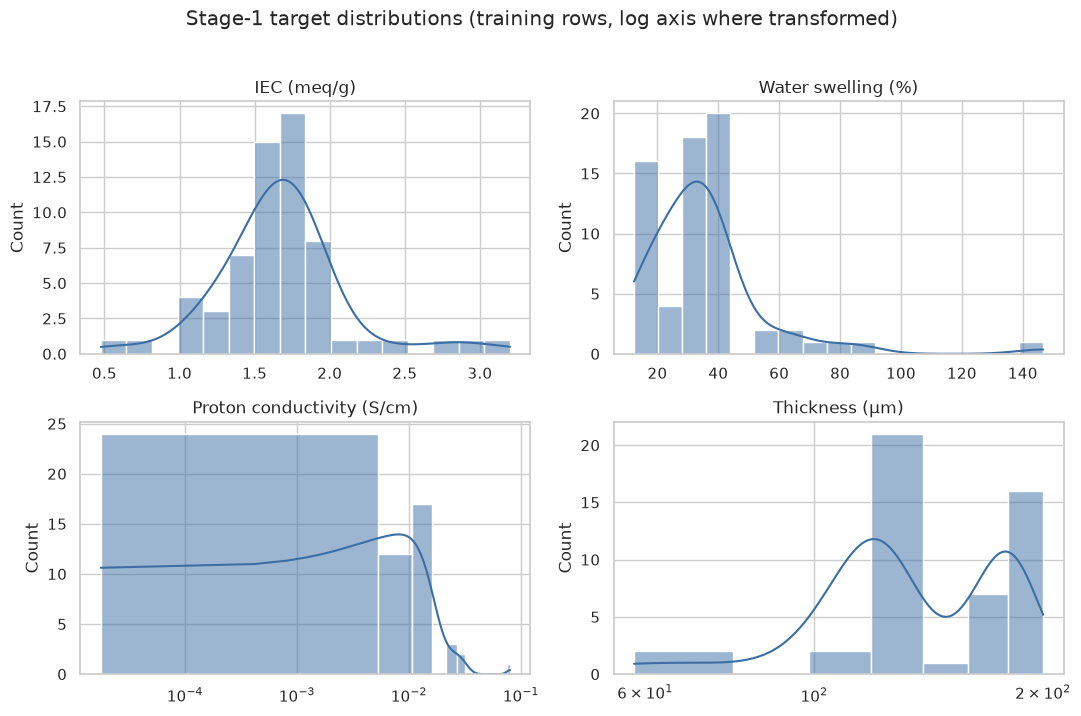

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, t in zip(axes.ravel(), TARGETS):
    sns.histplot(df_train[t].dropna(), kde=True, ax=ax, color="#3b6ea5")
    ax.set_title(TARGET_LABELS[t])
    ax.set_xlabel("")
    if t in LOG_TARGETS:
        ax.set_xscale("log")
fig.suptitle("Stage-1 target distributions (training rows, log axis where transformed)", y=1.02)
fig.tight_layout()
fig.savefig(FIGS / "fig_target_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


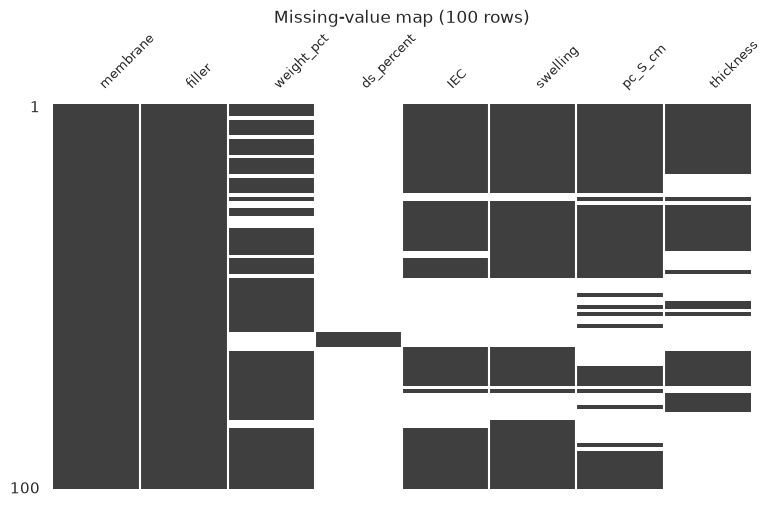

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
msno.matrix(df[["membrane", "filler", "weight_pct", "ds_percent", *TARGETS]],
            ax=ax, sparkline=False, fontsize=9)
ax.set_title("Missing-value map (100 rows)")
fig.savefig(FIGS / "fig_missingness.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


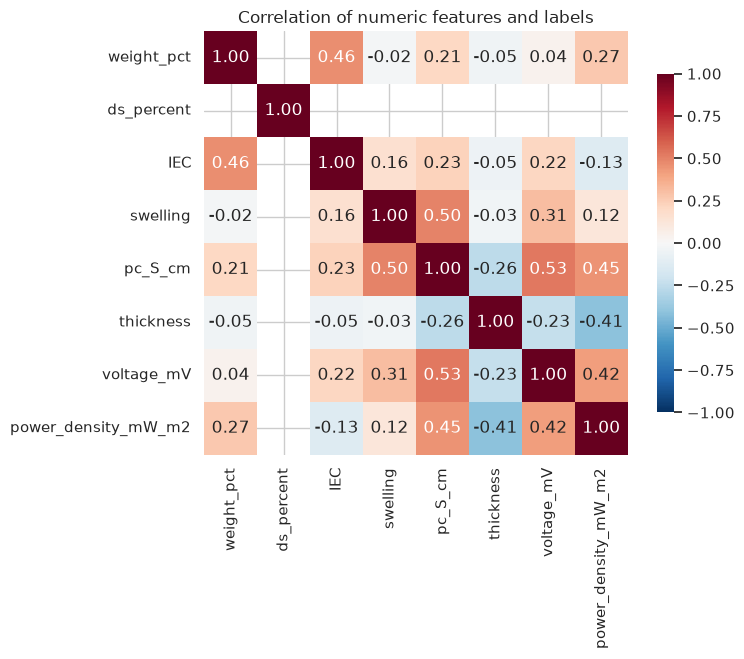

In [14]:
corr_cols = ["weight_pct", "ds_percent", *TARGETS, "voltage_mV", "power_density_mW_m2"]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(df_train[corr_cols].corr(numeric_only=True), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation of numeric features and labels")
fig.savefig(FIGS / "fig_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


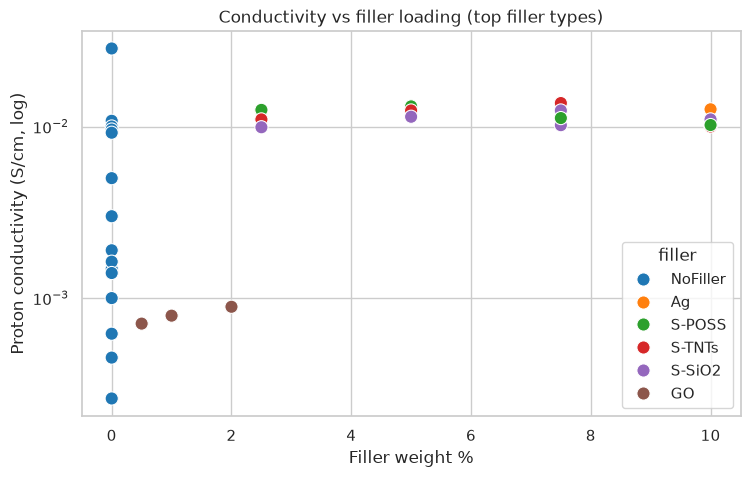

In [15]:
plot_df = df_train.dropna(subset=["pc_S_cm"])
top_fillers = plot_df.filler.value_counts().head(6).index
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.scatterplot(data=plot_df[plot_df.filler.isin(top_fillers)],
                x="weight_pct", y="pc_S_cm", hue="filler", s=90, ax=ax, palette="tab10")
ax.set_yscale("log")
ax.set_xlabel("Filler weight %")
ax.set_ylabel("Proton conductivity (S/cm, log)")
ax.set_title("Conductivity vs filler loading (top filler types)")
fig.savefig(FIGS / "fig_conductivity_vs_loading.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


In [16]:
# the signal that actually generalises: within-paper dose-response
rows = []
for t in TARGETS:
    sub = df_train.dropna(subset=[t, "weight_pct"])
    vals = sub.groupby("paper_id").apply(
        lambda d: d["weight_pct"].corr(np.log10(d[t]) if t in LOG_TARGETS else d[t])
        if d["weight_pct"].nunique() > 1 else np.nan,
        include_groups=False,
    ).dropna()
    rows.append({"target": TARGET_LABELS[t], "papers_with_dose_series": len(vals),
                 "mean_within_paper_r": round(vals.mean(), 3)})
dose_table = pd.DataFrame(rows)
print("Within-paper correlation between filler loading and property")
display(dose_table)


Within-paper correlation between filler loading and property


,target,papers_with_dose_series,mean_within_paper_r
0,IEC (meq/g),8,0.704
1,Water swelling (%),9,0.546
2,Proton conductivity (S/cm),8,0.507
3,Thickness (µm),8,0.398


## 9. Feature preprocessing

Categorical columns are one-hot encoded (`handle_unknown="ignore"` so Stage 3
candidates cannot crash the model); the numeric loading is median-imputed and scaled
for the linear model.

`ds_percent` is deliberately **excluded**: it is only populated for 4 rows, none of
which carry a Stage-1 label, so it would be a 100 %-empty feature in training.


In [17]:
CAT_FEATURES = ["membrane", "filler"]
NUM_FEATURES = ["weight_pct"]
FEATURES = CAT_FEATURES + NUM_FEATURES


def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=float),
             CAT_FEATURES),
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), NUM_FEATURES),
        ],
        remainder="drop",
    )


X_full = df[FEATURES]            # all 100 rows: used for the Stage-2 handoff
X_train = df_train[FEATURES]     # de-duplicated rows: used for fitting and CV
print("full matrix :", X_full.shape)
print("train matrix:", X_train.shape)
print("encoded width:", build_preprocessor().fit(X_full).get_feature_names_out().shape[0])


full matrix : (100, 3)
train matrix: (94, 3)
encoded width: 22


## 10. Models

Ridge is included deliberately: with ~60 rows and one-hot categoricals a regularised
linear model often generalises better across papers than a tree ensemble.


In [18]:
def model_zoo():
    return {
        "Baseline (mean)": DummyRegressor(strategy="mean"),
        "Ridge": Ridge(alpha=1.0),
        "RandomForest": RandomForestRegressor(
            n_estimators=600, min_samples_leaf=3, max_depth=6, max_features=0.6,
            random_state=RANDOM_STATE, n_jobs=-1),
        "ExtraTrees": ExtraTreesRegressor(
            n_estimators=600, min_samples_leaf=3, max_depth=6, max_features=0.6,
            random_state=RANDOM_STATE, n_jobs=-1),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_iter=300, learning_rate=0.05, max_leaf_nodes=8,
            min_samples_leaf=6, l2_regularization=1.0, random_state=RANDOM_STATE),
        "XGBoost": XGBRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=RANDOM_STATE, n_jobs=4, objective="reg:squarederror"),
        "LightGBM": LGBMRegressor(
            n_estimators=300, learning_rate=0.05, num_leaves=7,
            min_child_samples=5, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, random_state=RANDOM_STATE, verbose=-1),
    }


def fwd(target, y):
    return np.log10(y) if target in LOG_TARGETS else np.asarray(y, dtype=float)


def inv(target, y):
    return 10.0 ** np.asarray(y) if target in LOG_TARGETS else np.asarray(y)


def fit_predict(X_tr, y_tr, X_te, model, target):
    pipe = Pipeline([("pre", build_preprocessor()), ("model", clone(model))])
    pipe.fit(X_tr, fwd(target, y_tr))
    return pipe, inv(target, pipe.predict(X_te))


## 11. Cross-validation: grouped (primary) vs random (leaky)

The grouped split is the honest estimator. The random split is run **only** to
quantify how much leakage a naive `train_test_split` would inject, which is the
exact failure mode flagged in the pipeline design.


In [19]:
results = []
oof_store = {}       # (target, model) -> dict of arrays
leak_store = {}      # target -> {model: pooled R2}

for target in TARGETS:
    mask = df_train[target].notna()
    Xt = X_train[mask]
    yt = df_train.loc[mask, target]
    gt = df_train.loc[mask, "paper_id"]
    sno = df_train.loc[mask, "s_no"]

    cv = GroupKFold(n_splits=min(5, int(gt.nunique())))
    splits = list(cv.split(Xt, yt, gt))
    print(f"\n=== {TARGET_LABELS[target]} | n={len(yt)} | papers={gt.nunique()} "
          f"| folds={len(splits)} | transform={TARGET_TRANSFORM[target]} ===")

    leak_store[target] = {}
    for name, est in model_zoo().items():
        oof = np.full(len(yt), np.nan)
        fold_r2, fold_mae, fold_rmse = [], [], []

        for tr, te in splits:
            _pipe, pred = fit_predict(Xt.iloc[tr], yt.iloc[tr], Xt.iloc[te], est, target)
            oof[te] = pred
            fold_mae.append(mean_absolute_error(yt.iloc[te], pred))
            fold_rmse.append(root_mean_squared_error(yt.iloc[te], pred))
            if len(te) > 1 and yt.iloc[te].nunique() > 1:
                fold_r2.append(r2_score(yt.iloc[te], pred))

        pooled_r2 = r2_score(yt, oof)
        results.append({
            "target": TARGET_LABELS[target], "model": name, "n": len(yt),
            "R2_pooled": pooled_r2,
            "R2_fold_mean": np.mean(fold_r2) if fold_r2 else np.nan,
            "R2_fold_std": np.std(fold_r2) if fold_r2 else np.nan,
            "MAE": mean_absolute_error(yt, oof),
            "RMSE": root_mean_squared_error(yt, oof),
        })
        oof_store[(target, name)] = {"y": yt.values, "pred": oof,
                                     "s_no": sno.values, "paper": gt.values}
        print(f"  {name:22s} R2(pooled)={pooled_r2:+.3f}  "
              f"R2(fold)={results[-1]['R2_fold_mean']:+.3f}  "
              f"MAE={results[-1]['MAE']:.4g}  RMSE={results[-1]['RMSE']:.4g}")

metrics = pd.DataFrame(results)



=== IEC (meq/g) | n=62 | papers=17 | folds=5 | transform=linear ===
  Baseline (mean)        R2(pooled)=-0.061  R2(fold)=-0.209  MAE=0.2949  RMSE=0.4468
  Ridge                  R2(pooled)=+0.067  R2(fold)=-0.074  MAE=0.2856  RMSE=0.4191


  RandomForest           R2(pooled)=+0.067  R2(fold)=-0.099  MAE=0.2781  RMSE=0.4191


  ExtraTrees             R2(pooled)=-0.016  R2(fold)=-0.193  MAE=0.2979  RMSE=0.4374


  HistGradientBoosting   R2(pooled)=-0.051  R2(fold)=-0.586  MAE=0.3466  RMSE=0.4447


  XGBoost                R2(pooled)=+0.038  R2(fold)=-0.225  MAE=0.2952  RMSE=0.4256
  LightGBM               R2(pooled)=+0.120  R2(fold)=-0.278  MAE=0.2843  RMSE=0.4069

=== Water swelling (%) | n=66 | papers=19 | folds=5 | transform=linear ===
  Baseline (mean)        R2(pooled)=-0.046  R2(fold)=-0.581  MAE=12.64  RMSE=20.62


  Ridge                  R2(pooled)=-0.198  R2(fold)=-0.369  MAE=12.6  RMSE=22.07


... (8 outputs left out)

  RandomForest           R2(pooled)=-0.160  R2(fold)=-0.378  MAE=32.71  RMSE=36.65


  ExtraTrees             R2(pooled)=-0.415  R2(fold)=-0.675  MAE=32.88  RMSE=40.48


  HistGradientBoosting   R2(pooled)=-0.118  R2(fold)=-0.311  MAE=32.1  RMSE=35.97
  XGBoost                R2(pooled)=-0.880  R2(fold)=-1.030  MAE=36.74  RMSE=46.65


  LightGBM               R2(pooled)=-0.346  R2(fold)=-0.705  MAE=33.67  RMSE=39.48


In [20]:
# same models, random KFold -> leaky upper bound
print("Leakage check: pooled R² under a random split (NOT a valid estimate)")
leak_rows = []
for target in TARGETS:
    mask = df_train[target].notna()
    Xt, yt = X_train[mask], df_train.loc[mask, target]
    kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for name, est in model_zoo().items():
        if name == "Baseline (mean)":
            continue
        oof = np.full(len(yt), np.nan)
        for tr, te in kf.split(Xt):
            _p, pred = fit_predict(Xt.iloc[tr], yt.iloc[tr], Xt.iloc[te], est, target)
            oof[te] = pred
        leak_store[target][name] = r2_score(yt, oof)
        leak_rows.append({"target": TARGET_LABELS[target], "model": name,
                          "R2_random_LEAKY": r2_score(yt, oof)})

leak = pd.DataFrame(leak_rows)
leak_wide = leak.pivot(index="target", columns="model", values="R2_random_LEAKY")
grouped = metrics[metrics.model != "Baseline (mean)"].pivot(
    index="target", columns="model", values="R2_pooled")
display(leak_wide.round(3))
print("\nInflation (random − grouped), mean per target:")
display((leak_wide - grouped).round(3).assign(mean_inflation=(leak_wide - grouped).mean(axis=1).round(3)))


Leakage check: pooled R² under a random split (NOT a valid estimate)


model,ExtraTrees,HistGradientBoosting,LightGBM,RandomForest,Ridge,XGBoost
target,,,,,,
IEC (meq/g),0.412,0.064,0.088,0.347,0.429,0.304
Proton conductivity (S/cm),-0.066,-0.152,-0.184,-0.118,-0.123,0.064
Thickness (µm),-0.160,-0.166,-0.358,-0.059,0.040,-0.047
Water swelling (%),-0.047,-0.078,-0.061,-0.070,-0.022,0.097



Inflation (random − grouped), mean per target:


model,ExtraTrees,HistGradientBoosting,LightGBM,RandomForest,Ridge,XGBoost,mean_inflation
target,,,,,,,
IEC (meq/g),0.428,0.115,-0.033,0.280,0.362,0.267,0.237
Proton conductivity (S/cm),0.430,0.097,0.212,0.209,0.278,0.329,0.259
Thickness (µm),0.255,-0.048,-0.012,0.102,0.504,0.832,0.272
Water swelling (%),0.195,-0.068,-0.068,-0.029,0.177,0.288,0.082


## 12. Leaderboard


,target,model,n,R2_pooled,R2_fold_mean,R2_fold_std,MAE,RMSE
6,IEC (meq/g),LightGBM,62,0.1204,-0.2780,0.4829,0.2843,0.4069
2,IEC (meq/g),RandomForest,62,0.0669,-0.0993,0.2362,0.2781,0.4191
1,IEC (meq/g),Ridge,62,0.0666,-0.0741,0.1898,0.2856,0.4191
5,IEC (meq/g),XGBoost,62,0.0376,-0.2247,0.2358,0.2952,0.4256
3,IEC (meq/g),ExtraTrees,62,-0.0163,-0.1926,0.3286,0.2979,0.4374
4,IEC (meq/g),HistGradientBoosting,62,-0.0509,-0.5859,0.4285,0.3466,0.4447
0,IEC (meq/g),Baseline (mean),62,-0.0605,-0.2090,0.1815,0.2949,0.4468
14,Proton conductivity (S/cm),Baseline (mean),59,-0.2087,-0.6916,0.9765,0.0078,0.0129
18,Proton conductivity (S/cm),HistGradientBoosting,59,-0.2491,-0.7706,1.0498,0.0075,0.0131
19,Proton conductivity (S/cm),XGBoost,59,-0.2650,-0.4933,0.4929,0.0075,0.0132


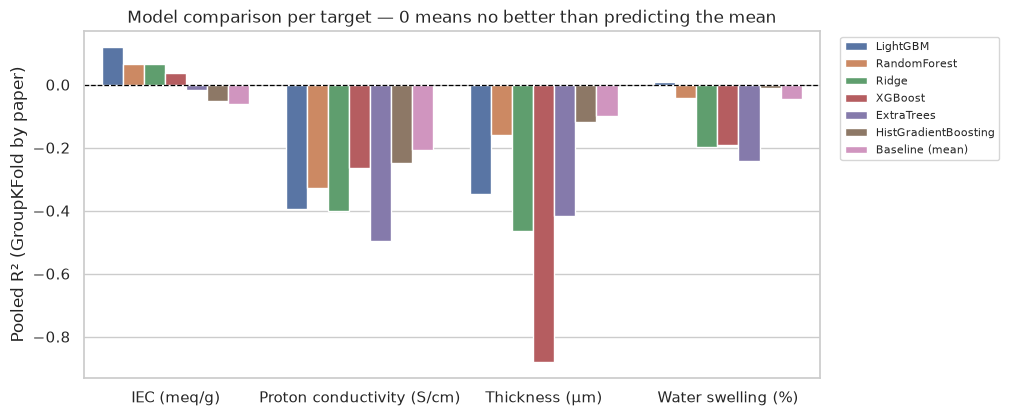

In [21]:
metrics = metrics.sort_values(["target", "RMSE"], ascending=[True, True])
display(metrics.round(4))
metrics.to_csv(OUT / "model_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(9.5, 4.5))
sns.barplot(data=metrics, x="target", y="R2_pooled", hue="model", ax=ax)
ax.axhline(0, color="black", lw=0.9, ls="--")
ax.set_ylabel("Pooled R² (GroupKFold by paper)")
ax.set_xlabel("")
ax.set_title("Model comparison per target — 0 means no better than predicting the mean")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.savefig(FIGS / "fig_model_leaderboard.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


In [22]:
best_models = (
    metrics[metrics.model != "Baseline (mean)"]
    .sort_values(["target", "RMSE"], ascending=[True, True])
    .groupby("target", as_index=False)
    .first()
)
baseline_rmse = metrics[metrics.model == "Baseline (mean)"].set_index("target")["RMSE"]
best_models["beats_baseline"] = best_models.apply(
    lambda r: r.RMSE < baseline_rmse[r.target] - 1e-12, axis=1)
display(best_models[["target", "model", "n", "R2_pooled", "MAE", "RMSE", "beats_baseline"]])


,target,model,n,R2_pooled,MAE,RMSE,beats_baseline
0,IEC (meq/g),LightGBM,62,0.120400,0.284281,0.406869,True
1,Proton conductivity (S/cm),HistGradientBoosting,59,-0.249094,0.007453,0.013122,False
2,Thickness (µm),HistGradientBoosting,49,-0.118001,32.101246,35.974602,False
3,Water swelling (%),LightGBM,66,0.006999,12.471129,20.087674,True


## 13. Refit the selected model per target and persist it


In [23]:
bundles = {}
best_lookup = {}
zoo = model_zoo()

print(f"{'target':32s} {'model':22s} {'n':>4s}")
for target, label in TARGET_LABELS.items():
    row = best_models[best_models.target == label].iloc[0]
    mask = df_train[target].notna()
    pipe = Pipeline([("pre", build_preprocessor()), ("model", clone(zoo[row.model]))])
    pipe.fit(X_train[mask], fwd(target, df_train.loc[mask, target]))

    bundle = {
        "target": target, "label": label, "model_name": row.model,
        "pipeline": pipe, "features": FEATURES,
        "transform": TARGET_TRANSFORM[target], "cv": row.to_dict(),
    }
    joblib.dump(bundle, MODELS / f"stage1_{target}.joblib")
    bundles[target] = bundle
    best_lookup[target] = row.model
    print(f"{label:32s} {row.model:22s} {int(mask.sum()):4d}")

json.dump({"best_models": best_lookup,
           "transforms": TARGET_TRANSFORM,
           "cv": metrics.round(5).to_dict(orient="records")},
          open(MODELS / "stage1_selection.json", "w"), indent=2)


target                           model                     n
IEC (meq/g)                      LightGBM                 62
Water swelling (%)               LightGBM                 66
Proton conductivity (S/cm)       HistGradientBoosting     59


Thickness (µm)                   HistGradientBoosting     49


## 14. Does the model transfer the dose-response?

The data contain a clear loading response, but the question for a model trained on
*other* papers is whether it reproduces that slope. Centring truth and prediction
within each paper removes the paper offset and isolates the slope.


,target,model,R2_absolute,R2_within_paper
0,IEC (meq/g),LightGBM,0.120,0.176
1,Water swelling (%),LightGBM,0.007,-0.559
2,Proton conductivity (S/cm),HistGradientBoosting,-0.249,-0.094
3,Thickness (µm),HistGradientBoosting,-0.118,-0.387


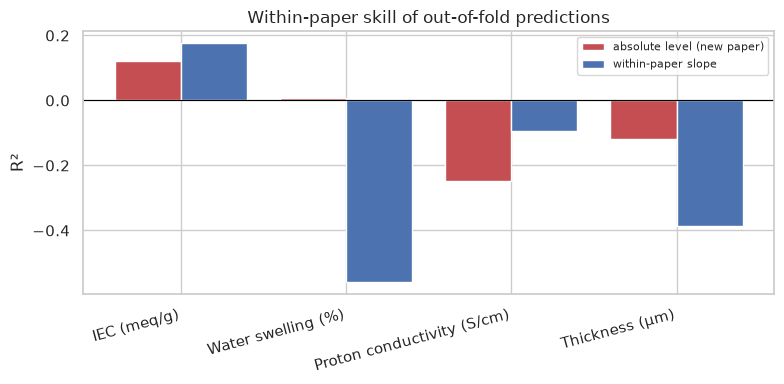

In [24]:
def within_paper_r2(y, pred, papers):
    d = pd.DataFrame({"y": y, "p": pred, "g": papers})
    d = d.groupby("g").filter(lambda x: len(x) > 1)
    if d.empty:
        return np.nan
    d = d.assign(yc=d.y - d.groupby("g").y.transform("mean"),
                 pc=d.p - d.groupby("g").p.transform("mean"))
    ss_res = ((d.yc - d.pc) ** 2).sum()
    ss_tot = (d.yc ** 2).sum()
    return 1 - ss_res / ss_tot if ss_tot > 0 else np.nan


rows = []
for target in TARGETS:
    name = best_lookup[target]
    st = oof_store[(target, name)]
    rows.append({
        "target": TARGET_LABELS[target],
        "model": name,
        "R2_absolute": r2_score(st["y"], st["pred"]),
        "R2_within_paper": within_paper_r2(st["y"], st["pred"], st["paper"]),
    })
transfer_diag = pd.DataFrame(rows)
display(transfer_diag.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(transfer_diag))
ax.bar(x - 0.2, transfer_diag.R2_absolute, 0.4, label="absolute level (new paper)", color="#c44e52")
ax.bar(x + 0.2, transfer_diag.R2_within_paper, 0.4, label="within-paper slope", color="#4c72b0")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(transfer_diag.target, rotation=15, ha="right")
ax.set_ylabel("R²")
ax.set_title("Within-paper skill of out-of-fold predictions")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "fig_dose_response_skill.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 15. Baseline-anchored mode — the recommended path for Stage 3

The failure in §11 is one of **identifiability**, not model capacity: two papers can
report the same filler at the same loading and differ by 3× because their base
membrane, casting method and test rig differ. If the neat-membrane value of the same
series is known, the paper offset cancels and only the filler increment has to be
learned.

Here we test exactly that: for every `(paper, membrane, filler)` series that has a
0 wt% anchor, model the **delta** from the anchor and reconstruct the absolute value.
Evaluation is leave-one-paper-out.


In [25]:
anchor_rows = []
for target in TARGETS:
    sub = df_train.dropna(subset=[target])
    for (pid, mem, fil), d in sub.groupby(["paper_id", "membrane", "filler"]):
        # inside a filler series a blank loading is the neat-membrane baseline (0 wt%)
        d = d.assign(w=d.weight_pct.fillna(0.0))
        if d.w.nunique() < 2:
            continue
        base = d.loc[d.w == 0, target]
        if base.empty:
            continue
        base = base.iloc[0]
        for _, r in d.iterrows():
            if r.w == 0:
                continue
            delta = (np.log10(r[target]) - np.log10(base)) if target in LOG_TARGETS \
                else (r[target] - base)
            anchor_rows.append({
                "target": target, "paper_id": pid, "membrane": mem, "filler": fil,
                "weight_pct": r.w, "delta": delta,
                "absolute": r[target], "base": base,
            })

anchor = pd.DataFrame(anchor_rows)
print("series-anchored pairs per target:")
display(anchor.target.value_counts().rename("pairs").to_frame())


series-anchored pairs per target:


,pairs
target,
IEC,19
swelling,19
pc_S_cm,19
thickness,12


In [26]:
from sklearn.model_selection import LeaveOneGroupOut

anchor_rows_out = []
for target in TARGETS:
    d = anchor[anchor.target == target]
    if len(d) < 6:
        continue
    Xa = d[["membrane", "filler", "weight_pct"]]
    ya = d["delta"].values
    ga = d["paper_id"]

    best = None
    for name in ["Ridge", "HistGradientBoosting"]:
        pred_delta = np.zeros(len(d))
        for tr, te in LeaveOneGroupOut().split(Xa, ya, ga):
            pipe = Pipeline([("pre", build_preprocessor()),
                             ("model", clone(model_zoo()[name]))])
            pipe.fit(Xa.iloc[tr], ya[tr])
            pred_delta[te] = pipe.predict(Xa.iloc[te])

        abs_pred = (10 ** (np.log10(d["base"].values) + pred_delta)) if target in LOG_TARGETS \
            else d["base"].values + pred_delta
        row = {
            "target": TARGET_LABELS[target], "model": name,
            "pairs": len(d), "papers": ga.nunique(),
            "delta_R2": r2_score(ya, pred_delta),
            "absolute_R2": r2_score(d["absolute"], abs_pred),
            "absolute_MAE": mean_absolute_error(d["absolute"], abs_pred),
        }
        anchor_rows_out.append(row)
        if best is None or row["absolute_MAE"] < best["absolute_MAE"]:
            best = row

anchored = pd.DataFrame(anchor_rows_out).sort_values(["target", "absolute_MAE"])
display(anchored.round(4))
anchored.to_csv(OUT / "anchored_mode_metrics.csv", index=False)

print("\nCompared with the un-anchored models of §12:")
compare = anchored.groupby("target").first()[["absolute_R2"]].join(
    best_models.set_index("target")[["R2_pooled"]])
compare.columns = ["anchored R2", "paper-only R2"]
display(compare.round(3))


,target,model,pairs,papers,delta_R2,absolute_R2,absolute_MAE
0,IEC (meq/g),Ridge,19,5,-0.3758,0.0615,0.4060
1,IEC (meq/g),HistGradientBoosting,19,5,-0.4644,0.0011,0.4197
5,Proton conductivity (S/cm),HistGradientBoosting,19,5,-0.3298,0.9142,0.0009
4,Proton conductivity (S/cm),Ridge,19,5,-0.4525,0.9049,0.0010
7,Thickness (µm),HistGradientBoosting,12,3,-0.0419,-0.0420,0.5833
6,Thickness (µm),Ridge,12,3,-0.6083,-0.6069,0.7164
2,Water swelling (%),Ridge,19,5,-0.4131,0.8379,2.2736
3,Water swelling (%),HistGradientBoosting,19,5,-0.4697,0.8314,2.5613



Compared with the un-anchored models of §12:


,anchored R2,paper-only R2
target,,
IEC (meq/g),0.062,0.120
Proton conductivity (S/cm),0.914,-0.249
Thickness (µm),-0.042,-0.118
Water swelling (%),0.838,0.007


### Reading this table

* Anchoring makes **water swelling** and **conductivity** usable (absolute R² ≈ 0.84
  and 0.90): most of the variance is the series baseline, and the loading correction
  is small enough that even an imperfect delta model helps.
* The **delta itself is still poorly predicted** (`delta_R2` < 0), so this is not a
  physically learned dose-response — it is bookkeeping around a known baseline.
* Only 5 papers provide both an anchor and a series, so these numbers are fragile.
* **Implication for Stage 3:** screen fillers only inside a membrane series whose
  neat value is known. Do not use Stage 1 to compare unrelated chemistries.


## 16. Stage-1 → Stage-2 handoff

Predict all four intermediates for **every** row, then keep the measured value where
one exists and the prediction where it does not. This is exactly the imputation table
Stage 2 needs.


In [27]:
handoff = df[["s_no", "paper_id", "paper_label", "membrane", "filler",
              "weight_pct", "ds_percent"]].copy()

for target in TARGETS:
    pred = inv(target, bundles[target]["pipeline"].predict(X_full))
    handoff[f"{target}_measured"] = df[target].values
    handoff[f"{target}_pred"] = pred
    handoff[f"{target}_final"] = handoff[f"{target}_measured"].fillna(handoff[f"{target}_pred"])
    handoff[f"{target}_source"] = np.where(
        handoff[f"{target}_measured"].notna(), "measured", "predicted")

pred_counts = pd.DataFrame({
    "measured": [int((handoff[f"{t}_source"] == "measured").sum()) for t in TARGETS],
    "predicted (imputed by Stage 1)": [int((handoff[f"{t}_source"] == "predicted").sum())
                                       for t in TARGETS],
}, index=[TARGET_LABELS[t] for t in TARGETS])
display(pred_counts)

handoff.to_csv(OUT / "stage1_predictions.csv", index=False)
print("wrote", OUT / "stage1_predictions.csv", handoff.shape)


,measured,predicted (imputed by Stage 1)
IEC (meq/g),68,32
Water swelling (%),72,28
Proton conductivity (S/cm),65,35
Thickness (µm),49,51


wrote /home/selvatharrun/Downloads/models/outputs/stage1_predictions.csv (100, 23)


## 17. Parity plots (out-of-fold predictions)


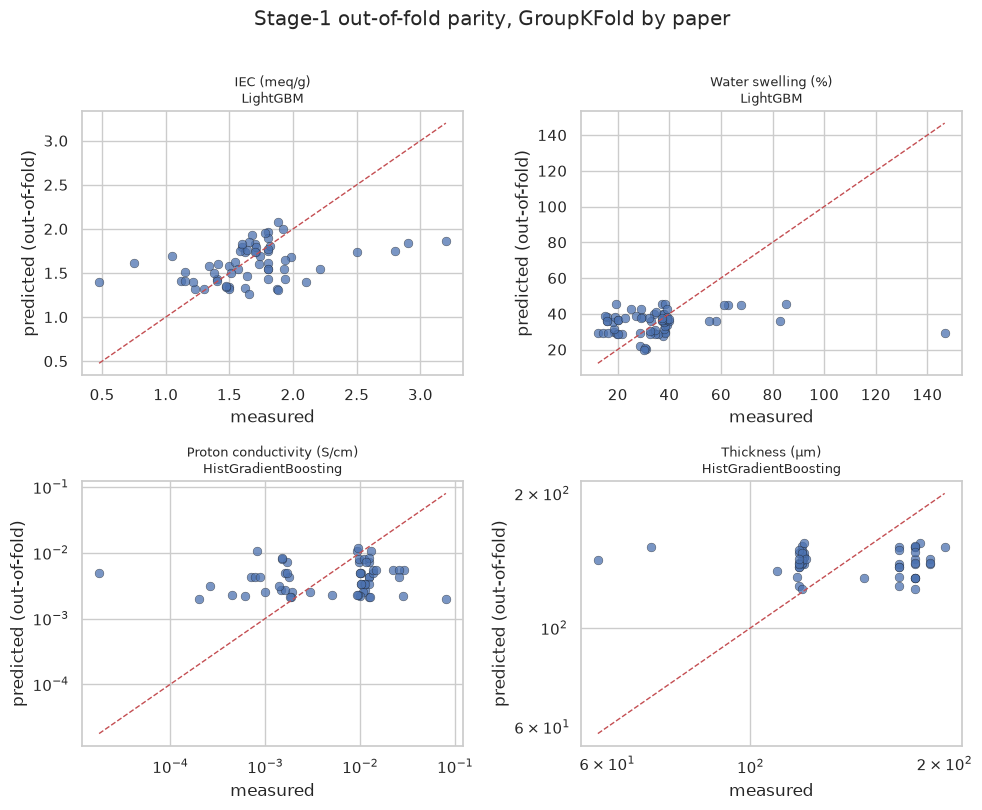

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), squeeze=False)
for ax, target in zip(axes.ravel(), TARGETS):
    name = best_lookup[target]
    st = oof_store[(target, name)]
    lo = min(st["y"].min(), st["pred"].min())
    hi = max(st["y"].max(), st["pred"].max())
    ax.scatter(st["y"], st["pred"], s=40, alpha=0.75, edgecolor="k", linewidth=0.3)
    ax.plot([lo, hi], [lo, hi], "r--", lw=1)
    if target in LOG_TARGETS:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("measured")
    ax.set_ylabel("predicted (out-of-fold)")
    ax.set_title(f"{TARGET_LABELS[target]}\n{name}", fontsize=9)
fig.suptitle("Stage-1 out-of-fold parity, GroupKFold by paper", y=1.01)
fig.tight_layout()
fig.savefig(FIGS / "fig_parity.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 18. What drives the predictions?

Permutation importance on the refit pipeline, computed in transformed space (the
ranking is unchanged by the monotone log transforms).


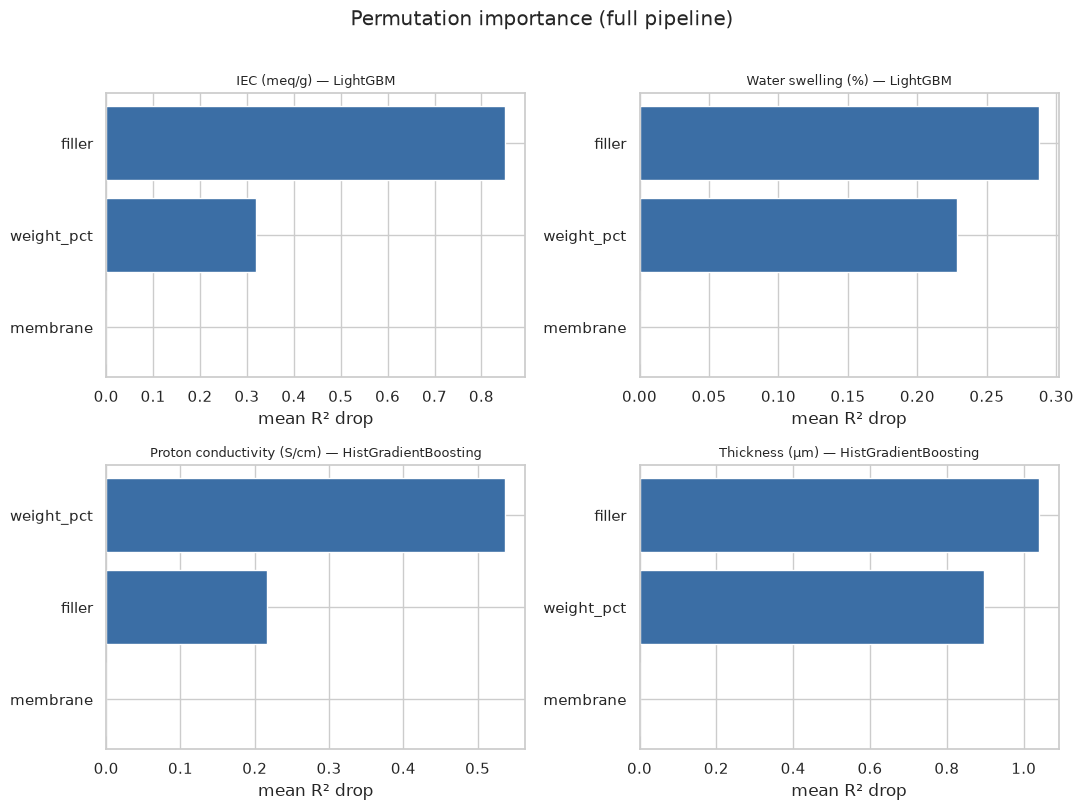

,feature,importance,target
0,filler,0.8510,IEC (meq/g)
1,weight_pct,0.3203,IEC (meq/g)
2,membrane,0.0000,IEC (meq/g)
3,filler,0.2873,Water swelling (%)
4,weight_pct,0.2289,Water swelling (%)
5,membrane,0.0000,Water swelling (%)
6,weight_pct,0.5373,Proton conductivity (S/cm)
7,filler,0.2159,Proton conductivity (S/cm)
8,membrane,0.0000,Proton conductivity (S/cm)
9,filler,1.0389,Thickness (µm)


In [29]:
imp_rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 8), squeeze=False)
for ax, target in zip(axes.ravel(), TARGETS):
    bundle = bundles[target]
    mask = df_train[target].notna()
    pi = permutation_importance(
        bundle["pipeline"], X_train[mask], fwd(target, df_train.loc[mask, target]),
        n_repeats=20, random_state=RANDOM_STATE, scoring="r2", n_jobs=4)
    imp = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean,
                        "target": TARGET_LABELS[target]})
    imp = imp.sort_values("importance", ascending=False, key=abs).reset_index(drop=True)
    imp_rows.append(imp)

    top = imp.head(3).iloc[::-1]
    ax.barh(top.feature, top.importance, color="#3b6ea5")
    ax.set_title(f"{TARGET_LABELS[target]} — {bundle['model_name']}", fontsize=9)
    ax.set_xlabel("mean R² drop")
fig.suptitle("Permutation importance (full pipeline)", y=1.01)
fig.tight_layout()
fig.savefig(FIGS / "fig_importance.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

importance = pd.concat(imp_rows, ignore_index=True)
display(importance.round(4))
importance.to_csv(OUT / "feature_importance.csv", index=False)


## 19. Data-quality report


In [30]:
report_rows = []
for _, r in df.iterrows():
    notes = []
    if r.thickness_unit:
        notes.append(f"thickness {r.thickness_raw} -> {r.thickness:.4g} µm ({r.thickness_unit})")
    if r.pc_ambiguous:
        notes.append("proton conductivity masked: " + PC_AMBIGUOUS[int(r.s_no)])
    if int(r.s_no) in PC_OVERRIDES:
        notes.append("proton conductivity corrected: " + PC_OVERRIDES[int(r.s_no)][1])
    if r.voltage_unit == "V->mV":
        notes.append(f"voltage {r.voltage_raw} V -> {r.voltage_mV:.0f} mV")
    if r.power_density_unit == "W/m2->mW/m2":
        notes.append(f"power density {r.power_density_raw} W/m² -> {r.power_density_mW_m2:.0f} mW/m²")
    if r.is_duplicate:
        notes.append(f"duplicate of S.No {int(r.duplicate_of_s_no)} (excluded from training)")
    if pd.notna(r.ds_percent):
        notes.append(f"DS {r.ds_percent}% moved from filler to ds_percent")
    if int(r.s_no) in (98, 99, 100):
        notes.append("membrane label corrected S-POSS -> SPEEK")
    for t in TARGETS:
        if pd.notna(r[t]) and ((outliers.s_no == r.s_no) & (outliers.target == t)).any():
            notes.append(f"{t} flagged as IQR outlier")
    if notes:
        report_rows.append({
            "s_no": int(r.s_no), "paper_id": r.paper_id,
            "membrane": r.membrane, "filler": r.filler,
            "weight_pct": r.weight_pct, "notes": " | ".join(notes),
        })

quality = pd.DataFrame(report_rows)
quality.to_csv(OUT / "data_quality_report.csv", index=False)
print(f"{len(quality)} rows carry a cleaning note")
display(quality.head(15))


51 rows carry a cleaning note


,s_no,paper_id,membrane,filler,weight_pct,notes
0,2,P02,SPEEK,NoFiller,0.0,pc_S_cm flagged as IQR outlier
1,3,P03,SPEEK,NoFiller,0.0,IEC flagged as IQR outlier
2,15,P06,SPEEK,S-TNTs,2.5,IEC flagged as IQR outlier
3,16,P06,SPEEK,S-TNTs,5.0,IEC flagged as IQR outlier
4,17,P06,SPEEK,S-TNTs,7.5,IEC flagged as IQR outlier
5,18,P06,SPEEK,S-TNTs,10.0,IEC flagged as IQR outlier
6,26,P09,SPEEK,TiO2,NaN,IEC flagged as IQR outlier
7,28,P10,SPEEK15,NoFiller,0.0,proton conductivity corrected: MFC DATA - DATA...
8,29,P10,SPEEK20,NoFiller,0.0,proton conductivity corrected: MFC DATA - DATA...
9,30,P10,SPEEK,GO,NaN,swelling flagged as IQR outlier


In [31]:
clean_cols = ["s_no", "paper_id", "paper_label", "membrane", "filler", "weight_pct",
              "ds_percent", "weight_missing", *TARGETS, "voltage_mV",
              "power_density_mW_m2", "thickness_unit", "pc_ambiguous",
              "is_duplicate", "duplicate_of_s_no"]
df[clean_cols].to_csv(OUT / "stage1_clean.csv", index=False)
print("wrote", OUT / "stage1_clean.csv", df[clean_cols].shape)


wrote /home/selvatharrun/Downloads/models/outputs/stage1_clean.csv (100, 18)


## 20. Summary


In [32]:
summary = best_models[["target", "model", "n", "R2_pooled", "MAE", "RMSE",
                       "beats_baseline"]].merge(
    transfer_diag[["target", "R2_within_paper"]], on="target", how="left")
summary["reliability"] = np.where(
    summary.beats_baseline & (summary.R2_pooled > 0.05), "usable",
    np.where(summary.beats_baseline, "marginal", "no better than mean"))
print("Selected Stage-1 models (GroupKFold by paper)")
display(summary.round(3))

print(f"\nrows in dataset          : {len(df)}")
print(f"rows used for training   : {len(df_train)}")
print(f"papers (CV groups)       : {df.paper_id.nunique()}")
print(f"complete-case rows       : {int(df[TARGETS].notna().all(axis=1).sum())}")
print(f"handoff file             : {OUT / 'stage1_predictions.csv'}")


Selected Stage-1 models (GroupKFold by paper)


,target,model,n,R2_pooled,MAE,RMSE,beats_baseline,R2_within_paper,reliability
0,IEC (meq/g),LightGBM,62,0.120,0.284,0.407,True,0.176,usable
1,Proton conductivity (S/cm),HistGradientBoosting,59,-0.249,0.007,0.013,False,-0.094,no better than mean
2,Thickness (µm),HistGradientBoosting,49,-0.118,32.101,35.975,False,-0.387,no better than mean
3,Water swelling (%),LightGBM,66,0.007,12.471,20.088,True,-0.559,marginal



rows in dataset          : 100
rows used for training   : 94
papers (CV groups)       : 30
complete-case rows       : 36
handoff file             : /home/selvatharrun/Downloads/models/outputs/stage1_predictions.csv


## 21. Caveats — read before using these models

* **R² near zero is the honest result, not a bug.** Only three inputs are available
  (membrane, filler, weight %). Across 30 papers each chemistry appears once, so the
  absolute property level of a *new* paper is not identifiable. The random-split table
  in §11 shows the 0.3–0.5 R² that a leaky split would have reported.
* **Only IEC is weakly predictable** (grouped R² ≈ 0.12, the one target that beats the
  mean predictor). Conductivity, swelling and thickness are statistically
  indistinguishable from predicting the paper-average, though their MAE is small in
  absolute terms (0.008 S/cm, 12 %, 32 µm).
* **The model does not transfer the dose-response** (§14): measured within-paper
  correlation is +0.7 (IEC) and +0.5 (conductivity), but out-of-fold predictions
  centred within a paper score ≈ 0. Global slopes are attenuated by paper offsets.
* **Anchoring is the practical fix** (§15): given a measured neat-membrane value for
  the same series, reconstruction R² reaches 0.84 (swelling) and 0.90 (conductivity).
  Use this mode for Stage 3 candidate screening.
* **n is small** (49–66 labels, 30 groups). Fold-to-fold spread is large; treat
  differences below ~0.1 R² as noise.
* **Six cross-paper duplicate rows** (S.No 91–97) were excluded from training but kept
  in `stage1_clean.csv` with `is_duplicate=True`. Two near-duplicates (S.No 99–100)
  differ by 0.1 meq/g and remain in the data.
* **Three conductivity rows were masked**, not imputed, because the source unit is
  ambiguous — see `outputs/data_quality_report.csv`.
* **Thickness for S.No 52–53** was assumed to be mm (→ 110/150 µm); confirm against
  the paper.
* **Water swelling of 146.69 %** (S.No 39) is plausible for a highly sulfonated
  membrane but is the single largest leverage point in that target.
* Stage 2 should consume `stage1_predictions.csv` and always prefer `*_measured`
  over `*_pred`.
* **To raise the ceiling**, add descriptors that transfer between papers: degree of
  sulfonation of the base membrane, base-membrane IEC, filler particle size / surface
  area, and temperature. Three categorical/numeric inputs cannot carry more.

print("\nStage 1 complete.")
